# 08. Experimento principal y estudio de cada algoritmo

Este cuaderno deja constancia de cómo se hicieron los dos últimos bloques de experimentos y los vuelve a comprobar:

1. **Experimento principal** (`src/experimento_principal.py`): las 100 fotos se clasifican en *lisas*, con *estructura* (líneas y bordes) y con *textura*, se toman las 6 más representativas de cada tipo y se aplican las 8 máscaras y los 3 métodos.
2. **Estudio de cada algoritmo** (`src/estudio_algoritmos.py`): para la media y para Bertalmio, cómo cambia el resultado al variar el tamaño del hueco, la forma de la máscara y el contraste, y los estudios propios de cada método (iteraciones y tolerancia en la media; valor de partida, ciclos, paso temporal y pasos de difusión en Bertalmio). Los de ejemplares los añade Alejandro.

Los datos están en `resultados/principal/` y `resultados/estudio_algoritmos/`. Aquí se (a) muestra qué fotos se eligieron y por qué, (b) se **repiten algunos casos** y se comprueba que dan el mismo error que los CSV, y (c) se enseñan las tablas y gráficas.

In [1]:
import os, sys, csv
sys.path.insert(0, os.path.abspath("../src"))
os.chdir(os.path.abspath(".."))      # carpeta del repositorio

import numpy as np
import experimento_principal, estudio_algoritmos, escenarios, experimentos, mascaras, metricas
print(metricas.informacion_equipo())

{'sistema': 'macOS-27.0.1-arm64-arm-64bit-Mach-O', 'procesador': 'arm', 'nucleos': 10, 'memoria_gb': 17.2, 'python': '3.14.6', 'numpy': '2.5.4', 'opencv': '5.0.0'}


## (a) Clasificación de las fotos

Energía = intensidad del gradiente; coherencia = cuánto se alinean los bordes en una dirección. Se eligen las 6 fotos más extremas de cada tipo.

In [2]:
clases = experimento_principal.clasificar("images/originales", 256, 6)
for tipo, lista in clases.items():
    print(f"\n{tipo}:")
    for nombre, energia, coherencia in lista:
        print(f"   {nombre[:30]:30s} energía {energia:7.1f}   coherencia {coherencia:.2f}")


lisa:
   photo-1583356016310-e6db1eb141 energía     3.0   coherencia 0.21
   photo-1550326456-3dccc0b6354d. energía     5.2   coherencia 0.24
   photo-1543083362-383ecbfe3142. energía     6.1   coherencia 0.49
   photo-1568151032356-412b3402a8 energía     8.7   coherencia 0.51
   photo-1581979693696-6a01e3ae0f energía     8.9   coherencia 0.55
   photo-1469938880222-00039554fd energía    11.1   coherencia 0.24

estructura:
   photo-1591567462086-5563d5e255 energía    77.0   coherencia 0.85
   photo-1473366311188-fb0d178ade energía    77.3   coherencia 0.79
   photo-1464725516711-da37f63878 energía    90.9   coherencia 0.74
   photo-1566689423506-9b918d4fdc energía   117.5   coherencia 0.72
   photo-1516057406-5fc186f6cafb. energía   161.9   coherencia 0.69
   photo-1571548570333-33a16016fb energía    85.0   coherencia 0.59

textura:
   photo-1441802910857-d6c72bdc8f energía   259.3   coherencia 0.06
   photo-1551601499-7be122716610. energía   185.3   coherencia 0.08
   photo-159036566

In [3]:
import matplotlib.pyplot as plt
fig, ejes = plt.subplots(3, 6, figsize=(15, 7.5))
for fila, (tipo, lista) in zip(ejes, clases.items()):
    for eje, (nombre, _, _) in zip(fila, lista):
        eje.imshow(experimentos.cargar_imagen(os.path.join("images/originales", nombre), 256)); eje.axis("off")
    fila[0].set_title(tipo, loc="left", fontsize=11)
plt.tight_layout(); plt.show()

/var/folders/zl/wy2yghk54bs962jds4h1j8r40000gn/T/ipykernel_34748/236822462.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


## (b) Se repiten casos y se comprueba contra los CSV

Se vuelven a ejecutar, en este momento, 3 fotos del experimento principal (una de cada tipo) con la máscara `cuadrado_32` y los tres métodos, y 4 casos del estudio de algoritmos. El error tiene que coincidir con el guardado, porque los métodos son deterministas.

In [4]:
principal = {(r["imagen"], r["mascara"], r["metodo"]): r for r in csv.DictReader(open("resultados/principal/principal.csv", encoding="utf-8"))}
print(f"{'tipo':11s} {'método':11s} {'MSE ahora':>10s} {'MSE CSV':>10s} {'tiempo ahora':>13s} {'tiempo CSV':>11s}  ¿igual?")
for tipo, lista in clases.items():
    nombre = lista[0][0]
    foto = experimentos.cargar_imagen(os.path.join("images/originales", nombre), 256)
    nombre_mascara, _, mascara = [m for m in experimentos.definir_mascaras(foto.shape[:2], 42) if m[0].startswith("cuadrado_32")][0]
    _, salida = escenarios.ejecutar_caso(foto, mascara)
    for metodo, (_, t, it, med) in salida.items():
        antes = principal[(nombre, nombre_mascara, metodo)]
        igual = abs(float(antes["mse_hueco"]) - med["mse_hueco"]) < 0.01
        print(f"{tipo:11s} {metodo:11s} {med['mse_hueco']:10.2f} {float(antes['mse_hueco']):10.2f} {t:13.3f} {float(antes['tiempo_s']):11.3f}  {'sí' if igual else 'NO'}")

tipo        método       MSE ahora    MSE CSV  tiempo ahora  tiempo CSV  ¿igual?


lisa        media            11.48      11.48         0.030       0.029  sí
lisa        Bertalmio        13.63      13.63         0.539       0.535  sí
lisa        ejemplares       23.08      23.08         3.045       3.031  sí


estructura  media           480.72     480.72         0.032       0.032  sí
estructura  Bertalmio       452.57     452.57         2.205       2.199  sí
estructura  ejemplares      392.32     392.32         2.801       2.818  sí


textura     media          2316.79    2316.79         0.028       0.028  sí
textura     Bertalmio      2385.75    2385.75         2.190       2.319  sí
textura     ejemplares     3762.08    3762.08         1.228       1.294  sí


In [5]:
comunes, fotos = estudio_algoritmos.casos(4)
guardado = {}
for metodo in ("media", "Bertalmio"):
    for r in csv.DictReader(open(f"resultados/estudio_algoritmos/{metodo}.csv", encoding="utf-8")):
        guardado[(metodo, r["estudio"], r["valor"], r["caso"])] = r
muestra = [c for c in comunes if c[0] == "tamaño" and c[1] == 32][::5][:2] + [c for c in comunes if c[0].startswith("contraste (borde)") and c[1] == 80][:1] + [c for c in comunes if c[0] == "forma" and c[1] == "círculo"][:1]
print(f"{'estudio':22s} {'valor':>8s} {'método':10s} {'MSE ahora':>10s} {'MSE CSV':>10s}  ¿igual?")
for estudio, valor, caso, tipo_imagen, foto, mascara, contraste in muestra:
    for metodo in ("media", "Bertalmio"):
        _, salida = escenarios.ejecutar_caso(foto, mascara, (metodo,))
        antes = guardado[(metodo, estudio, str(valor), caso)]
        igual = abs(float(antes["mse_hueco"]) - salida[metodo][3]["mse_hueco"]) < 0.01
        print(f"{estudio:22s} {str(valor):>8s} {metodo:10s} {salida[metodo][3]['mse_hueco']:10.2f} {float(antes['mse_hueco']):10.2f}  {'sí' if igual else 'NO'}")

estudio                   valor método      MSE ahora    MSE CSV  ¿igual?
tamaño                       32 media            1.29       1.29  sí


tamaño                       32 Bertalmio        1.36       1.36  sí
tamaño                       32 media          879.76     879.76  sí


tamaño                       32 Bertalmio     1070.83    1070.83  sí
contraste (borde)            80 media          360.50     360.50  sí


contraste (borde)            80 Bertalmio      112.12     112.12  sí
forma                   círculo media            1.24       1.24  sí


forma                   círculo Bertalmio        1.31       1.31  sí


## (c) Resultados guardados

### Experimento principal

# Experimento principal: los tres métodos sobre fotos clasificadas por tipo

18 fotos (432 ejecuciones), 8 máscaras por foto. MSE sobre el hueco: menor es mejor.

### Por tipo de foto

| tipo de foto | casos | MSE mediano media | MSE mediano Bertalmio | MSE mediano ejemplares | tiempo mediano media (s) | tiempo mediano Bertalmio (s) | tiempo mediano ejemplares (s) | gana (media / Bertalmio / ejemplares) |
|---|---:|---:|---:|---:|---:|---:|---:|---|
| lisa | 48 | 10.1 | 9.5 | 21.7 | 0.02 | 2.16 | 2.30 | 25 / 20 / 3 |
| estructura | 48 | 460.9 | 406.3 | 519.5 | 0.03 | 4.35 | 1.78 | 22 / 17 / 9 |
| textura | 48 | 1362.8 | 1472.3 | 2974.5 | 0.05 | 4.42 | 2.63 | 35 / 12 / 1 |

### Por tipo de máscara

| máscara | casos | MSE mediano media | MSE mediano Bertalmio | MSE mediano ejemplares | tiempo mediano media (s) | tiempo mediano Bertalmio (s) | tiempo mediano ejemplares (s) | gana (media / Bertalmio / ejemplares) |
|---|---:|---:|---:|---:|---:|---:|---:|---|
| cuadrado | 54 | 561.0 | 528.9 | 1520.7 | 0.03 | 2.20 | 2.06 | 27 / 21 / 6 |
| circulo | 36 | 195.9 | 228.2 | 403.0 | 0.04 | 2.14 | 2.46 | 24 / 8 / 4 |
| aranazo | 18 | 151.4 | 174.2 | 280.8 | 0.01 | 4.27 | 2.48 | 14 / 2 / 2 |
| motas | 18 | 269.0 | 214.0 | 308.7 | 0.04 | 13.20 | 1.21 | 11 / 7 / 0 |
| irregular | 18 | 564.7 | 469.1 | 1335.0 | 0.17 | 4.38 | 4.16 | 6 / 11 / 1 |

### Por tipo de foto y de máscara

| foto · máscara | casos | MSE mediano media | MSE mediano Bertalmio | MSE mediano ejemplares | tiempo mediano media (s) | tiempo mediano Bertalmio (s) | tiempo mediano ejemplares (s) | gana (media / Bertalmio / ejemplares) |
|---|---:|---:|---:|---:|---:|---:|---:|---|
| lisa · cuadrado | 18 | 7.4 | 7.2 | 25.5 | 0.02 | 1.17 | 2.29 | 7 / 10 / 1 |
| lisa · circulo | 12 | 4.4 | 5.0 | 14.5 | 0.02 | 1.49 | 2.54 | 8 / 3 / 1 |
| lisa · aranazo | 6 | 13.7 | 16.3 | 35.1 | 0.01 | 4.31 | 2.73 | 5 / 1 / 0 |
| lisa · motas | 6 | 20.3 | 4.3 | 14.9 | 0.04 | 10.23 | 1.32 | 2 / 4 / 0 |
| lisa · irregular | 6 | 82.5 | 89.5 | 282.2 | 0.16 | 4.37 | 4.86 | 3 / 2 / 1 |
| estructura · cuadrado | 18 | 943.8 | 1024.9 | 1504.5 | 0.04 | 2.20 | 1.41 | 8 / 5 / 5 |
| estructura · circulo | 12 | 333.4 | 329.8 | 403.0 | 0.06 | 3.44 | 2.38 | 6 / 3 / 3 |
| estructura · aranazo | 6 | 216.9 | 240.4 | 337.0 | 0.01 | 3.94 | 1.66 | 4 / 1 / 1 |
| estructura · motas | 6 | 269.0 | 214.0 | 308.7 | 0.03 | 10.31 | 0.76 | 3 / 3 / 0 |
| estructura · irregular | 6 | 777.8 | 518.9 | 831.3 | 0.19 | 4.38 | 2.85 | 1 / 5 / 0 |
| textura · cuadrado | 18 | 1556.8 | 1660.1 | 3836.5 | 0.04 | 2.21 | 2.63 | 12 / 6 / 0 |
| textura · circulo | 12 | 2031.9 | 2096.2 | 4278.9 | 0.11 | 3.66 | 2.57 | 10 / 2 / 0 |
| textura · aranazo | 6 | 375.8 | 424.9 | 941.4 | 0.01 | 4.90 | 3.18 | 5 / 0 / 1 |
| textura · motas | 6 | 882.6 | 1184.6 | 1400.6 | 0.05 | 14.86 | 1.53 | 6 / 0 / 0 |
| textura · irregular | 6 | 2502.7 | 2446.2 | 4662.3 | 0.19 | 4.39 | 5.27 | 2 / 4 / 0 |


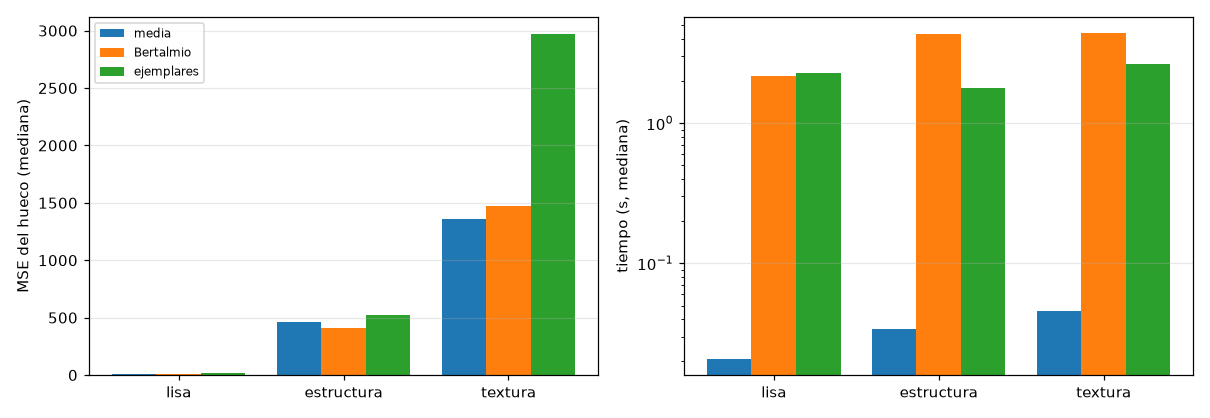

In [6]:
from IPython.display import Markdown, Image, display
display(Markdown(open("resultados/principal/principal.md", encoding="utf-8").read()))
display(Image(filename="resultados/principal/principal_por_tipo.png"))

### Estudio de cada algoritmo

# Estudio de cada algoritmo

Medianas sobre los casos de cada fila. MSE sobre el hueco (menor es mejor).

## tamaño

| valor | media: MSE | media: tiempo (s) | media: iteraciones | Bertalmio: MSE | Bertalmio: tiempo (s) | Bertalmio: iteraciones |
|---|---:|---:|---:|---:|---:|---:|
| 8 | 269.5 | 0.00 | 51 | 209.7 | 0.29 | 205 |
| 16 | 432.2 | 0.01 | 129 | 478.2 | 0.92 | 483 |
| 24 | 635.4 | 0.01 | 230 | 599.3 | 1.58 | 600 |
| 32 | 618.1 | 0.03 | 310 | 627.1 | 2.17 | 600 |
| 48 | 949.8 | 0.11 | 564 | 917.4 | 3.59 | 600 |
| 64 | 1394.0 | 0.24 | 719 | 1401.9 | 5.51 | 600 |

## forma

| valor | media: MSE | media: tiempo (s) | media: iteraciones | Bertalmio: MSE | Bertalmio: tiempo (s) | Bertalmio: iteraciones |
|---|---:|---:|---:|---:|---:|---:|
| cuadrado | 618.1 | 0.03 | 310 | 627.1 | 2.18 | 600 |
| círculo | 546.8 | 0.04 | 376 | 494.4 | 2.38 | 600 |
| tira 8×128 | 416.6 | 0.02 | 157 | 495.0 | 2.57 | 600 |
| arañazo | 209.3 | 0.03 | 58 | 203.1 | 17.91 | 600 |
| motas | 288.2 | 0.13 | 189 | 283.2 | 18.66 | 600 |
| irregular | 854.6 | 0.07 | 516 | 859.3 | 2.82 | 600 |

## contraste (borde)

| valor | media: MSE | media: tiempo (s) | media: iteraciones | Bertalmio: MSE | Bertalmio: tiempo (s) | Bertalmio: iteraciones |
|---|---:|---:|---:|---:|---:|---:|
| 10 | 6.9 | 0.01 | 150 | 6.0 | 0.35 | 95 |
| 20 | 24.1 | 0.02 | 213 | 9.3 | 2.16 | 600 |
| 40 | 89.0 | 0.03 | 275 | 31.0 | 2.17 | 600 |
| 80 | 344.7 | 0.03 | 336 | 94.2 | 2.18 | 600 |
| 160 | 1356.9 | 0.04 | 398 | 280.8 | 2.18 | 600 |
| 240 | 3035.1 | 0.04 | 434 | 520.0 | 2.19 | 600 |

## contraste (línea fina)

| valor | media: MSE | media: tiempo (s) | media: iteraciones | Bertalmio: MSE | Bertalmio: tiempo (s) | Bertalmio: iteraciones |
|---|---:|---:|---:|---:|---:|---:|
| 10 | 4.8 | 0.00 | 41 | 5.5 | 0.36 | 100 |
| 20 | 18.4 | 0.01 | 60 | 20.1 | 0.43 | 118 |
| 40 | 73.9 | 0.01 | 86 | 83.6 | 0.62 | 171 |
| 80 | 291.4 | 0.01 | 122 | 322.7 | 0.80 | 218 |
| 160 | 848.3 | 0.02 | 174 | 962.0 | 1.78 | 494 |
| 240 | 1004.1 | 0.02 | 192 | 1137.1 | 1.81 | 504 |

## propio: iteraciones

| valor | media: MSE | media: tiempo (s) | media: iteraciones | Bertalmio: MSE | Bertalmio: tiempo (s) | Bertalmio: iteraciones |
|---|---:|---:|---:|---:|---:|---:|
| 10 | 808.3 | 0.00 | 10 | - | - | - |
| 50 | 606.3 | 0.01 | 50 | - | - | - |
| 100 | 579.3 | 0.01 | 100 | - | - | - |
| 250 | 611.3 | 0.03 | 250 | - | - | - |
| 500 | 617.9 | 0.05 | 500 | - | - | - |
| 1000 | 616.0 | 0.10 | 1000 | - | - | - |
| hasta converger | 616.5 | 0.07 | 665 | - | - | - |

## propio: tolerancia

| valor | media: MSE | media: tiempo (s) | media: iteraciones | Bertalmio: MSE | Bertalmio: tiempo (s) | Bertalmio: iteraciones |
|---|---:|---:|---:|---:|---:|---:|
| 1 | 709.2 | 0.00 | 19 | - | - | - |
| 0.1 | 601.8 | 0.01 | 106 | - | - | - |
| 0.01 | 618.1 | 0.03 | 310 | - | - | - |
| 0.001 | 616.5 | 0.07 | 665 | - | - | - |

## propio: valor de partida

| valor | media: MSE | media: tiempo (s) | media: iteraciones | Bertalmio: MSE | Bertalmio: tiempo (s) | Bertalmio: iteraciones |
|---|---:|---:|---:|---:|---:|---:|
| difusión simple | - | - | - | 627.1 | 2.20 | 600 |
| media plana | - | - | - | 838.9 | 2.15 | 600 |
| ruido | - | - | - | 1862.7 | 2.16 | 600 |

## propio: máximo de ciclos

| valor | media: MSE | media: tiempo (s) | media: iteraciones | Bertalmio: MSE | Bertalmio: tiempo (s) | Bertalmio: iteraciones |
|---|---:|---:|---:|---:|---:|---:|
| 25 | - | - | - | 630.2 | 0.12 | 25 |
| 50 | - | - | - | 630.4 | 0.22 | 50 |
| 100 | - | - | - | 623.5 | 0.39 | 100 |
| 200 | - | - | - | 610.8 | 0.76 | 200 |
| 600 | - | - | - | 627.1 | 2.20 | 600 |

## propio: paso temporal

| valor | media: MSE | media: tiempo (s) | media: iteraciones | Bertalmio: MSE | Bertalmio: tiempo (s) | Bertalmio: iteraciones |
|---|---:|---:|---:|---:|---:|---:|
| 0.05 | - | - | - | 627.3 | 2.20 | 600 |
| 0.1 | - | - | - | 627.1 | 2.19 | 600 |
| 0.2 | - | - | - | 636.9 | 2.19 | 600 |

## propio: pasos de difusión por ciclo

| valor | media: MSE | media: tiempo (s) | media: iteraciones | Bertalmio: MSE | Bertalmio: tiempo (s) | Bertalmio: iteraciones |
|---|---:|---:|---:|---:|---:|---:|
| 0 | - | - | - | 577.6 | 1.98 | 600 |
| 2 | - | - | - | 627.1 | 2.19 | 600 |
| 4 | - | - | - | 642.9 | 2.40 | 600 |


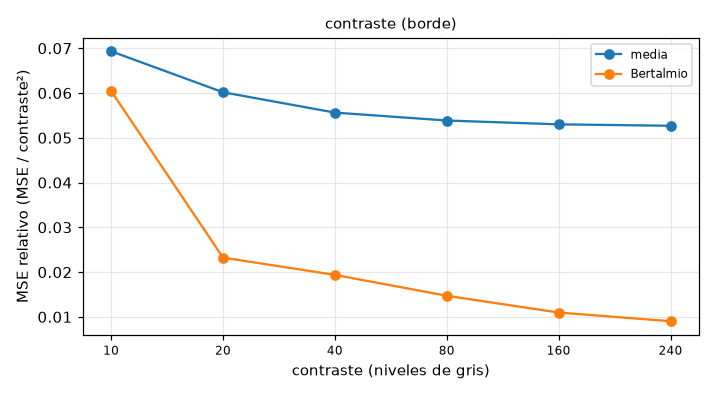

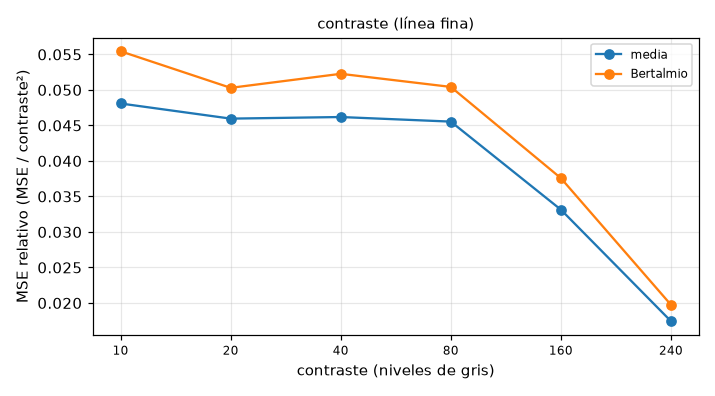

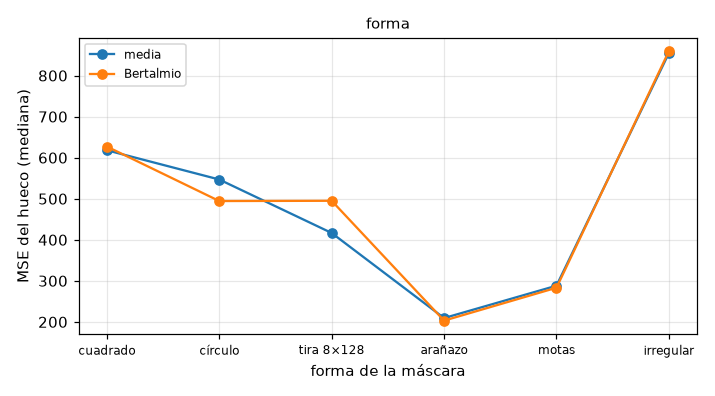

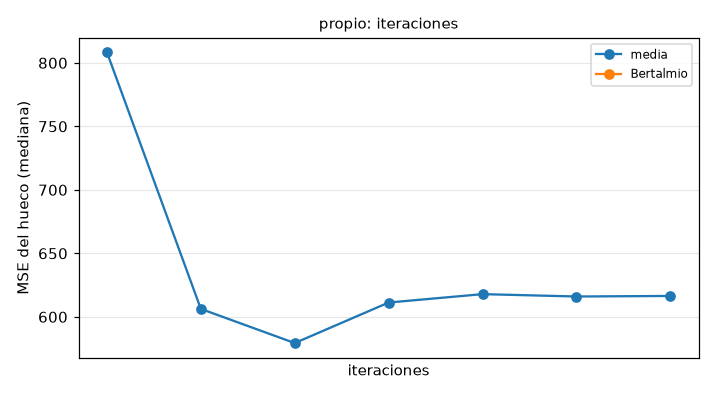

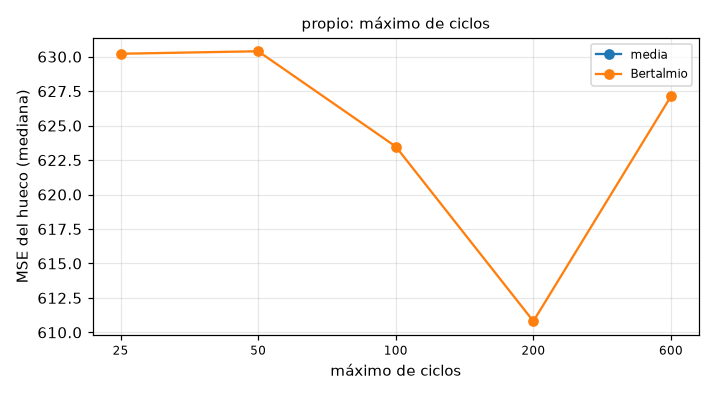

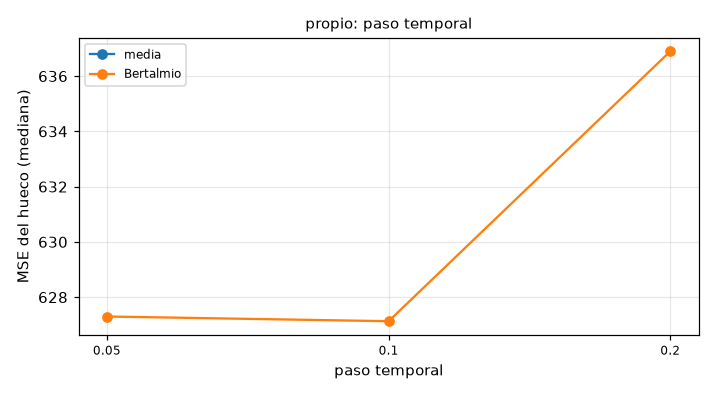

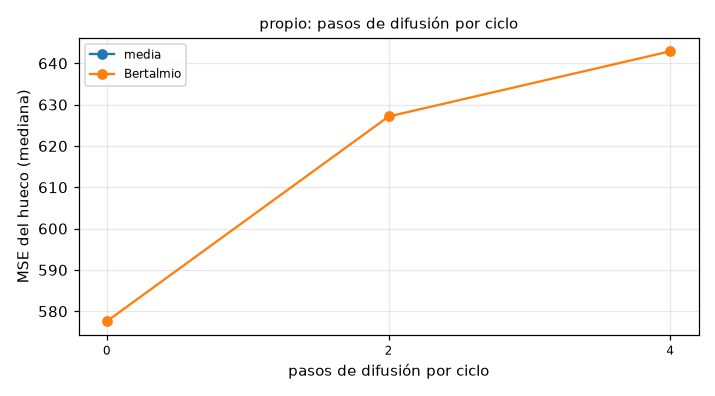

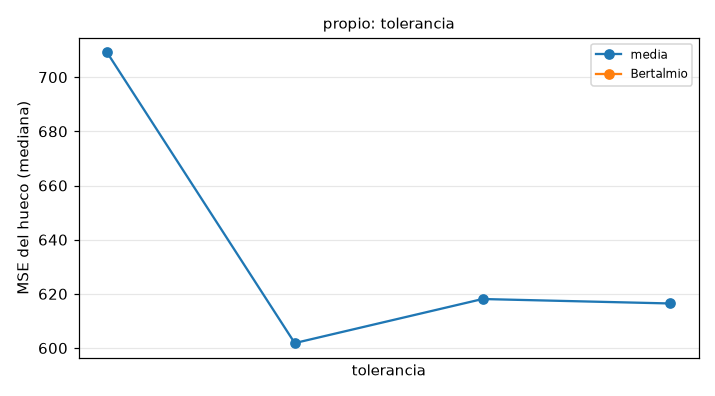

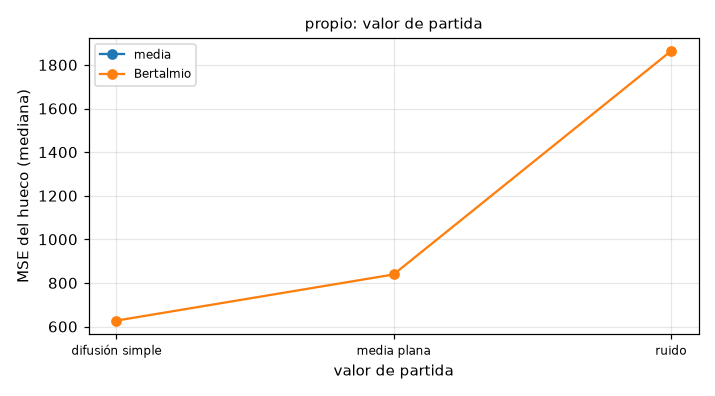

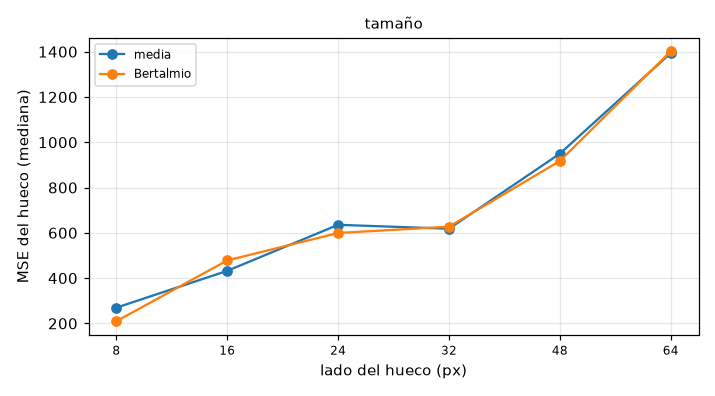

In [7]:
display(Markdown(open("resultados/estudio_algoritmos/estudio.md", encoding="utf-8").read()))
carpeta = "resultados/estudio_algoritmos"
for nombre in sorted(f for f in os.listdir(carpeta) if f.endswith(".png")):
    display(Image(filename=os.path.join(carpeta, nombre)))